In [3]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import tqdm

from IPython.display import HTML, display



In [4]:
plt.rcParams.update({
    "font.size": 13,
    "figure.figsize": (6.2, 3.5),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
})
J = 1.0
KB = 1.0

In [5]:
def total_energy(spins, B):
    n = spins.shape[0]
    energy = 0.0
    for i in range(n):
        for j in range(n):
            for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                neighbor = spins[(i + di) % n, (j + dj) % n]
                energy -= J * spins[i, j] * neighbor
    energy /= 2 # remove doubled counts
    for i in range(n):
        for j in range(n):
            energy -= B * spins[i, j]

In [6]:
@njit
def flip_energy(spins, B, i, j):
    n = spins.shape[0]
    neighbors = spins[(i - 1) % n, j] + spins[(i + 1) % n, j] + spins[i, (j - 1) % n] + spins[i, (j + 1) % n]
    return 2 * J * spins[i, j] * neighbors + 2 * B * spins[i,j]


In [7]:
@njit
def metropolis_step(spins, temperature, B, rng):
    i, j = rng.integers(0, spins.shape[0], size=2)
    delta_energy = flip_energy(spins, B, i, j)
    if delta_energy <= 0 or rng.random() < np.exp(-delta_energy / (KB * temperature)):
        spins[i, j] *= -1
        return 1
    return 0

In [8]:
@njit
def advance_ising(spins, temperature, B, sweeps, rng):
    n = spins.shape[0]
    magnetization = np.empty(sweeps + 1)
    magnetization[0] = spins.mean()
    accepted = 0
    for sweep in range(1, sweeps + 1):
        for _ in range(n * n):
            accepted += metropolis_step(spins, temperature, B, rng)
        magnetization[sweep] = spins.mean()
    return (magnetization, accepted)


def run_ising(spins, temperature, B, n, sweeps, seed):
    rng = np.random.default_rng(seed)
    magnetization, accepted = advance_ising(spins, temperature, B, sweeps, rng)
    return (spins, magnetization, accepted / (sweeps * n * n))



# Problem A

In [9]:
N = 100
SWEEPS = 1000
SEED = 200479013
T = 2.0
BURNIN = 200

B = 1

# all up
spins = np.ones((N,N))
final_spins, m_values_up, acceptance = run_ising(spins, T, B, N, SWEEPS, SEED)

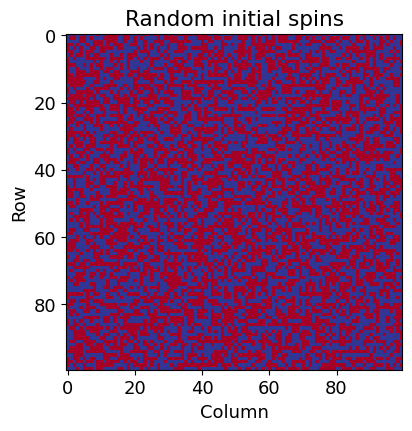

In [10]:
# random spins

rng = np.random.default_rng(SEED)
spins = rng.choice([1, -1], size = spins.shape)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(spins, cmap="RdYlBu", vmin=-1, vmax=1)
ax.set(title=f"Random initial spins",
    xlabel="Column", ylabel="Row")
plt.show()
final_spins, m_values_rand, acceptance = run_ising(spins, T, B, N, SWEEPS, SEED)



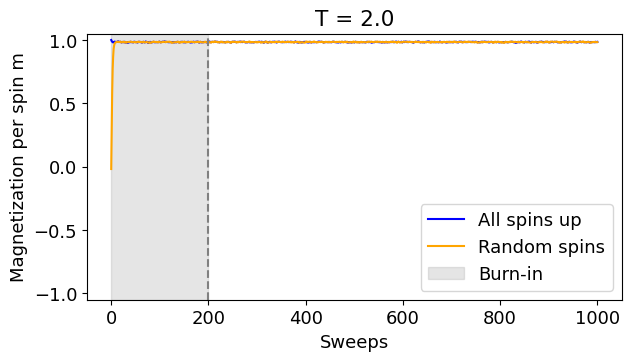

In [11]:
sweep_axis = np.arange(m_values_up.shape[0])
fig, ax = plt.subplots()
ax.plot(sweep_axis, m_values_up, color="blue", label="All spins up")
ax.plot(sweep_axis, m_values_rand, color="orange", label="Random spins")
ax.axvspan(0, BURNIN, color="gray", alpha=0.2, label="Burn-in")
ax.axvline(BURNIN, color="gray", linestyle="--")
ax.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
    title="T = 2.0", ylim=(-1.05, 1.05))
ax.legend()
plt.show()


# Problem B

TypeError: run_ising() missing 1 required positional argument: 'seed'

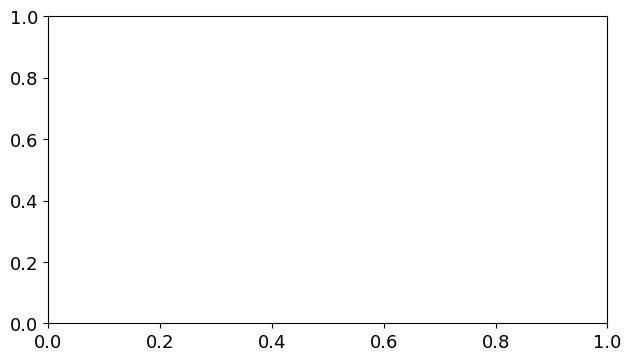

In [12]:
temps = np.arange(1,4+0.2,0.2)
temp_m_means = []
temp_sd = []

BURNIN = 200
SWEEPS = 1000

fig, ax = plt.subplots()

for i, temp in enumerate(temps):
    spins = np.ones_like(spins)
    final_spins, m_values, acceptance = run_ising(spins, temp, N, SWEEPS, SEED + i)
    
    samples = m_values[BURNIN + 1:]
    mean = samples.mean()
    sd = samples.std()
    temp_m_means.append(mean)
    temp_sd.append(sd)
    
    if (i % 5 == 0):
        ax.plot(sweep_axis, m_values, label=f"T = {temp:.1f}")

ax.axvspan(0, BURNIN, color="gray", alpha=0.2, label="Burn-in")
ax.axvline(BURNIN, color="gray", linestyle="--")
ax.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
    title="Temperature sweep", ylim=(-1.05, 1.05))
ax.legend()
plt.show()


<ErrorbarContainer object of 3 artists>

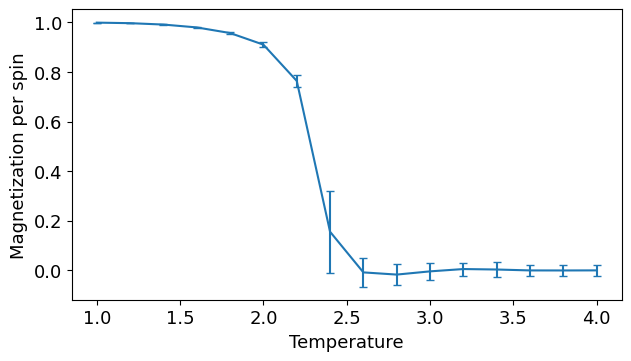

In [ ]:
plt.figure()
plt.xlabel("Temperature")
plt.ylabel("Magnetization per spin")
plt.errorbar(temps, temp_m_means, yerr=temp_sd,capsize=3)